# 05 · Comparación y conclusiones

En este notebook juntamos los dos componentes. La sección 1 compara el aprendizaje supervisado con el no supervisado y responde las ocho preguntas de comparación del enunciado. Las estrategias para reducir las cancelaciones y las conclusiones van en las secciones 2 y 3.

## 1. Comparación entre aprendizaje supervisado y no supervisado

### 1.1 De dónde salen las cifras

Este notebook no vuelve a entrenar la SVM ni a repetir los análisis de los notebooks 03 y 04. La búsqueda de hiperparámetros de la SVM tardó más de una hora (notebook 03, sección 4.2), y los resultados ya están en los notebooks 03 y 04. Las tablas de la 1.2 copian esas cifras, y cada fila dice de qué notebook y sección sale, para que se puedan revisar.

Lo único que calculamos aquí es el cruce de la 1.3, porque necesita los dos enfoques sobre las mismas reservas y no está en ningún notebook anterior. Para ese cruce usamos la regresión logística, que se reentrena en segundos, y los segmentos de K-Means, que se rehacen igual con la misma semilla.

### 1.2 Resumen de métricas

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import cross_val_predict
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

sys.path.insert(0, str(Path("../src").resolve()))

from preprocesamiento import (
    COLUMNAS_PREDICTORAS,
    GRUPO,
    OBJETIVO,
    SEMILLA,
    crear_particionador,
    crear_preprocesador,
)

RUTA_ENTRENAMIENTO = Path("../data/processed/entrenamiento.csv.gz")
METRICAS = ["F1", "Recall", "Precision", "ROC-AUC", "PR-AUC"]

COLOR_PRINCIPAL = "#087F8C"
COLOR_SECUNDARIO = "#A0AEC0"
COLOR_RIESGO = "#916313"

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 100)

In [2]:
resumen_supervisado = pd.DataFrame([
    ("Referencia: todas canceladas", "Validación cruzada", 0.452, 1.000, 0.292, 0.500, 0.292, "03 · 2.3"),
    ("Logística (C=1, corte 0,086)", "Validación cruzada", 0.573, 0.733, 0.470, 0.751, 0.553, "03 · 4.4"),
    ("SVM (C=3, gamma='scale', corte −0,009)", "Validación cruzada", 0.589, 0.750, 0.485, 0.767, 0.575, "03 · 4.4"),
    ("Logística (C=1, corte 0,086)", "Prueba", 0.575, 0.736, 0.471, 0.754, 0.559, "03 · 4.5"),
    ("SVM (C=3, gamma='scale', corte −0,009)", "Prueba", 0.590, 0.750, 0.486, 0.771, 0.579, "03 · 4.5"),
    ("Logística (corte 0)", "Llegadas de 2017", 0.548, 0.758, 0.430, 0.727, 0.482, "03 · 6.2"),
    ("SVM (corte 0)", "Llegadas de 2017", 0.555, 0.730, 0.447, 0.729, 0.483, "03 · 6.2"),
], columns=["modelo", "evaluación", *METRICAS, "fuente"])

print("Componente supervisado")
resumen_supervisado

Componente supervisado


,modelo,evaluación,F1,Recall,Precision,ROC-AUC,PR-AUC,fuente
0,Referencia: todas canceladas,Validación cruzada,0.452,1.000,0.292,0.500,0.292,03 · 2.3
1,"Logística (C=1, corte 0,086)",Validación cruzada,0.573,0.733,0.470,0.751,0.553,03 · 4.4
2,"SVM (C=3, gamma='scale', corte −0,009)",Validación cruzada,0.589,0.750,0.485,0.767,0.575,03 · 4.4
3,"Logística (C=1, corte 0,086)",Prueba,0.575,0.736,0.471,0.754,0.559,03 · 4.5
4,"SVM (C=3, gamma='scale', corte −0,009)",Prueba,0.590,0.750,0.486,0.771,0.579,03 · 4.5
5,Logística (corte 0),Llegadas de 2017,0.548,0.758,0.430,0.727,0.482,03 · 6.2
6,SVM (corte 0),Llegadas de 2017,0.555,0.730,0.447,0.729,0.483,03 · 6.2


In [3]:
resumen_agrupamiento = pd.DataFrame([
    ("K-Means", 4, "Entrenamiento completo (63.351)", 0.249, 1.392, 17407.5, 45.5, np.nan, "04 · 2.3"),
    ("K-Means", 4, "Muestra de 10.000", 0.247, 1.393, 2729.0, 46.15, 1.000, "04 · 3.5"),
    ("Ward", 3, "Muestra de 10.000", 0.280, 1.230, 2269.8, 76.81, 0.281, "04 · 3.5"),
    ("Ward", 4, "Muestra de 10.000", 0.189, 1.615, 2189.5, 48.73, 0.422, "04 · 3.5"),
], columns=["método", "k", "reservas", "Silhouette", "Davies-Bouldin", "Calinski-Harabasz",
            "grupo más grande (%)", "ARI con K-Means (k = 4)", "fuente"])

resumen_segmentos = pd.DataFrame([
    ("Escapadas de fin de semana", 13.4, 21.6, 22.1, 9.9),
    ("Anticipadas y largas", 45.5, 34.6, 35.3, 54.0),
    ("Última hora entre semana", 25.5, 18.6, 18.9, 16.2),
    ("Viajes con menores", 15.5, 37.3, 34.5, 19.8),
    ("Todas las reservas", 100.0, 29.2, 29.2, 100.0),
], columns=["segmento de K-Means", "reservas (%)", "cancelación en entrenamiento (%)",
            "cancelación en prueba (%)", "aporte a las cancelaciones (%)"]).assign(fuente="04 · 4.1 y 4.3")

otras_cifras = pd.DataFrame([
    ("Cancelación en el CSV original (sin limpiar)", "37,0 %", "01 · 1.6"),
    ("Filas idénticas a otra en el CSV original", "31.994", "01 · 2.3"),
    ("Recall de la logística sin pesos de clase", "0,263", "03 · 2.3"),
    ("Reservas de ajuste que terminan como vectores de soporte (SVM)", "65,4 %", "03 · 3.3"),
    ("Perfiles de entrenamiento con reservas canceladas y no canceladas", "1.713 (4.030 reservas)", "03 · 3.3"),
    ("Cancelaciones de prueba que detecta la SVM", "3.470 de 4.628", "03 · 4.5"),
    ("Falsas alarmas de la SVM en prueba", "3.664 de 11.211 que sí llegaron", "03 · 4.5"),
    ("Memoria de la matriz de distancias de Ward con todas las reservas", "16,1 GB", "04 · 3.2"),
    ("ARI de los segmentos con otras muestras del 80 % (promedio y mínimo)", "0,991 y 0,975", "04 · 4.2"),
    ("ARI de los segmentos con otras semillas (9 de 10 / la que se sale)", "0,977 o más / 0,460", "04 · 4.2"),
    ("ARI entre el modelo de entrenamiento y un K-Means ajustado con la prueba", "0,961", "04 · 4.2"),
    ("V de Cramér entre segmento y cancelación", "0,170", "04 · 4.3"),
    ("Varianza que conservan los dos primeros componentes de PCA", "56,9 % (35,7 % y 21,2 %)", "04 · 5.1"),
    ("Conservación local con 15 vecinos (PCA / t-SNE)", "0,914 / 0,997", "04 · 5.2"),
], columns=["cifra", "valor", "fuente"])

print("Componente no supervisado")
display(resumen_agrupamiento)
print("Segmentos y cancelación (calculada después de agrupar)")
display(resumen_segmentos)
print("Otras cifras que usamos en las respuestas")
otras_cifras

Componente no supervisado


,método,k,reservas,Silhouette,Davies-Bouldin,Calinski-Harabasz,grupo más grande (%),ARI con K-Means (k = 4),fuente
0,K-Means,4,Entrenamiento completo (63.351),0.249,1.392,17407.5,45.50,NaN,04 · 2.3
1,K-Means,4,Muestra de 10.000,0.247,1.393,2729.0,46.15,1.000,04 · 3.5
2,Ward,3,Muestra de 10.000,0.280,1.230,2269.8,76.81,0.281,04 · 3.5
3,Ward,4,Muestra de 10.000,0.189,1.615,2189.5,48.73,0.422,04 · 3.5


Segmentos y cancelación (calculada después de agrupar)


,segmento de K-Means,reservas (%),cancelación en entrenamiento (%),cancelación en prueba (%),aporte a las cancelaciones (%),fuente
0,Escapadas de fin de semana,13.4,21.6,22.1,9.9,04 · 4.1 y 4.3
1,Anticipadas y largas,45.5,34.6,35.3,54.0,04 · 4.1 y 4.3
2,Última hora entre semana,25.5,18.6,18.9,16.2,04 · 4.1 y 4.3
3,Viajes con menores,15.5,37.3,34.5,19.8,04 · 4.1 y 4.3
4,Todas las reservas,100.0,29.2,29.2,100.0,04 · 4.1 y 4.3


Otras cifras que usamos en las respuestas


,cifra,valor,fuente
0,Cancelación en el CSV original (sin limpiar),"37,0 %",01 · 1.6
1,Filas idénticas a otra en el CSV original,31.994,01 · 2.3
2,Recall de la logística sin pesos de clase,"0,263",03 · 2.3
3,Reservas de ajuste que terminan como vectores de soporte (SVM),"65,4 %",03 · 3.3
4,Perfiles de entrenamiento con reservas canceladas y no canceladas,1.713 (4.030 reservas),03 · 3.3
5,Cancelaciones de prueba que detecta la SVM,3.470 de 4.628,03 · 4.5
6,Falsas alarmas de la SVM en prueba,3.664 de 11.211 que sí llegaron,03 · 4.5
7,Memoria de la matriz de distancias de Ward con todas las reservas,"16,1 GB",04 · 3.2
8,ARI de los segmentos con otras muestras del 80 % (promedio y mínimo),"0,991 y 0,975",04 · 4.2
9,ARI de los segmentos con otras semillas (9 de 10 / la que se sale),"0,977 o más / 0,460",04 · 4.2


### 1.3 Los dos enfoques sobre las mismas reservas

Las tablas muestran cada enfoque por su lado. Falta una pregunta que solo se responde juntándolos: **¿el modelo supervisado distingue el riesgo dentro de cada segmento, o el segmento ya dice todo lo que el modelo sabe?** Si el segmento bastara, al hotel le daría lo mismo usar uno u otro.

Para responderla, a cada reserva de entrenamiento le ponemos dos cosas:

- **Su segmento de K-Means.** Repetimos la preparación y el K-Means de la sección 2 del notebook 04, con la misma semilla, y comprobamos que salen exactamente los mismos tamaños.
- **Su puntaje de riesgo de la logística**, con `C=1`, pesos balanceados y el corte de 0,086 de la sección 4.3 del notebook 03. Usamos predicciones fuera de partición: el puntaje de cada reserva sale de un modelo que no la vio, entrenado en las mismas cinco particiones agrupadas del notebook 03. Así no tocamos la prueba, que ya se usó.

Usamos la logística y no la SVM porque esta se demora mucho más en reentrenarse. En prueba la logística queda apenas 0,015 de F1 por debajo de la SVM (tabla de la 1.2), así que para este cruce es una buena aproximación.

In [4]:
TAMANOS_SEGMENTOS_NOTEBOOK_04 = [8497, 28852, 16156, 9846]
NOMBRES_SEGMENTOS = {
    0: "Escapadas de fin de semana",
    1: "Anticipadas y largas",
    2: "Última hora entre semana",
    3: "Viajes con menores",
}
CORTE_LOGISTICA = 0.086
CUARTOS_RIESGO = ["1 · el 25 % de menor riesgo", "2", "3", "4 · el 25 % de mayor riesgo"]


def segmentos_de_kmeans(datos):
    """Rehace la preparación y el K-Means (k = 4) de la sección 2 del notebook 04."""
    variables = datos.assign(
        proporcion_fin_semana=datos["stays_in_weekend_nights"] / datos["total_noches"],
        con_menores=(datos["children"] + datos["babies"]).gt(0).astype(int),
    )
    preparador = ColumnTransformer([
        ("logaritmo", make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()),
         ["lead_time", "total_noches", "total_huespedes"]),
        ("escaladas", StandardScaler(), ["proporcion_fin_semana"]),
        ("binarias", "passthrough", ["con_menores"]),
        ("categoricas", OneHotEncoder(min_frequency=0.01, handle_unknown="infrequent_if_exist", sparse_output=False),
         ["customer_type", "distribution_channel"]),
    ])
    matriz = preparador.fit_transform(variables)
    return KMeans(n_clusters=4, n_init=10, random_state=SEMILLA).fit_predict(matriz)


entrenamiento = pd.read_csv(RUTA_ENTRENAMIENTO)
X_entrenamiento = entrenamiento[list(COLUMNAS_PREDICTORAS)]
y_entrenamiento = entrenamiento[OBJETIVO]

segmentos = segmentos_de_kmeans(entrenamiento)
assert np.bincount(segmentos).tolist() == TAMANOS_SEGMENTOS_NOTEBOOK_04

logistica = Pipeline([
    ("preprocesamiento", crear_preprocesador()),
    ("modelo", LogisticRegression(class_weight="balanced", max_iter=1_000, random_state=SEMILLA)),
])
particiones = list(crear_particionador().split(X_entrenamiento, y_entrenamiento, entrenamiento[GRUPO]))
puntaje = cross_val_predict(logistica, X_entrenamiento, y_entrenamiento, cv=particiones, method="decision_function")
marcada = puntaje > CORTE_LOGISTICA

print("Segmentos iguales a los del notebook 04:", np.bincount(segmentos).tolist())
print(f"Logística fuera de partición: F1 {f1_score(y_entrenamiento, marcada):.3f}, "
      f"Recall {recall_score(y_entrenamiento, marcada):.3f}, Precision {precision_score(y_entrenamiento, marcada):.3f}, "
      f"ROC-AUC {roc_auc_score(y_entrenamiento, puntaje):.3f}, marcadas {marcada.mean():.1%}")

Segmentos iguales a los del notebook 04: [8497, 28852, 16156, 9846]
Logística fuera de partición: F1 0.573, Recall 0.733, Precision 0.470, ROC-AUC 0.751, marcadas 45.6%


Los segmentos salen idénticos a los del notebook 04, y la logística da las mismas cifras de la sección 4.3 del notebook 03 (F1 de 0,573 y 45,6 % de reservas marcadas). Con eso, medimos el modelo dentro de cada segmento.

,reservas,cancelación (%),ROC-AUC dentro del segmento,marcadas como canceladas (%),Recall,Precision,cancelaciones detectadas que aporta (%)
Escapadas de fin de semana,8497.0,21.643,0.718,29.081,0.543,0.404,7.358
Anticipadas y largas,28852.0,34.649,0.741,57.022,0.808,0.491,59.584
Última hora entre semana,16156.0,18.612,0.723,22.004,0.470,0.397,10.417
Viajes con menores,9846.0,37.254,0.710,64.788,0.837,0.481,22.641
Todas las reservas,63351.0,29.220,0.751,45.551,0.733,0.470,100.000


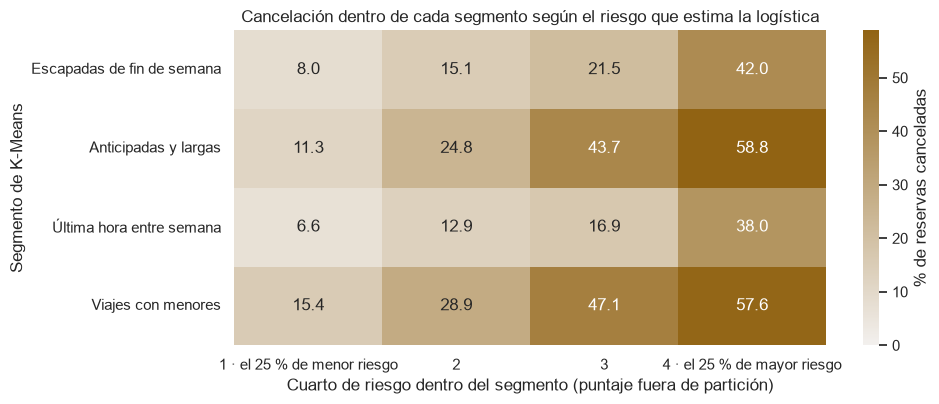

In [5]:
def modelo_en_segmento(mascara):
    """Cancelación observada y desempeño de la logística en un grupo de reservas."""
    reales, puntajes, marcas = y_entrenamiento[mascara], puntaje[mascara], marcada[mascara]
    return {
        "reservas": int(mascara.sum()),
        "cancelación (%)": reales.mean() * 100,
        "ROC-AUC dentro del segmento": roc_auc_score(reales, puntajes),
        "marcadas como canceladas (%)": marcas.mean() * 100,
        "Recall": recall_score(reales, marcas),
        "Precision": precision_score(reales, marcas),
        "cancelaciones detectadas que aporta (%)": (marcas & reales.eq(1).to_numpy()).sum()
        / (marcada & y_entrenamiento.eq(1).to_numpy()).sum() * 100,
    }


modelo_por_segmento = pd.DataFrame({
    **{nombre: modelo_en_segmento(segmentos == numero) for numero, nombre in NOMBRES_SEGMENTOS.items()},
    "Todas las reservas": modelo_en_segmento(np.ones(len(segmentos), dtype=bool)),
}).T
display(modelo_por_segmento.round(3))

riesgo = pd.DataFrame({
    "segmento": pd.Series(segmentos).map(NOMBRES_SEGMENTOS),
    "puntaje": puntaje,
    "cancelada": y_entrenamiento.to_numpy(),
})
riesgo["cuarto de riesgo"] = riesgo.groupby("segmento")["puntaje"].transform(
    lambda valores: pd.qcut(valores, q=len(CUARTOS_RIESGO), labels=CUARTOS_RIESGO).astype(str)
)
cancelacion_por_cuarto = (
    riesgo.pivot_table(index="segmento", columns="cuarto de riesgo", values="cancelada", aggfunc="mean")
    .loc[list(NOMBRES_SEGMENTOS.values()), CUARTOS_RIESGO] * 100
)

fig, ax = plt.subplots(figsize=(10, 4.2))
sns.heatmap(cancelacion_por_cuarto, cmap=sns.light_palette(COLOR_RIESGO, as_cmap=True), annot=True, fmt=".1f",
            vmin=0, cbar_kws={"label": "% de reservas canceladas"}, ax=ax)
ax.set_title("Cancelación dentro de cada segmento según el riesgo que estima la logística")
ax.set_xlabel("Cuarto de riesgo dentro del segmento (puntaje fuera de partición)")
ax.set_ylabel("Segmento de K-Means")
plt.tight_layout()
plt.show()

**¿Qué vemos?**

- **El modelo sigue separando el riesgo dentro de cada segmento.** Su ROC-AUC dentro de cada uno va de 0,710 (viajes con menores) a 0,741 (anticipadas y largas), apenas por debajo del 0,751 con todas las reservas juntas. En el mapa se ve lo que eso significa: dentro de las anticipadas, el cuarto de menor riesgo cancela 11,3 % y el de mayor riesgo 58,8 %; dentro de las de última hora, 6,6 % contra 38,0 %. Esas diferencias son mucho más grandes que las que hay entre segmentos, que van de 18,6 % a 37,3 %. O sea que el segmento no reemplaza al puntaje: dos reservas del mismo segmento pueden tener riesgos muy distintos.
- **El segmento, a su vez, muestra dónde se concentra el riesgo.** Con un solo corte, la logística marca el 57,0 % de las anticipadas y el 64,8 % de los viajes con menores, pero solo el 29,1 % de las escapadas y el 22,0 % de las de última hora. De las cancelaciones que el modelo detecta, el 82,2 % sale de esos dos primeros segmentos (59,6 % y 22,6 %).
- **Ese único corte deja algo por fuera.** En los dos segmentos de poca anticipación el modelo detecta apenas la mitad de las cancelaciones (Recall de 0,543 en las escapadas y de 0,470 en las de última hora), contra 0,808 y 0,837 en los otros dos. No es que ahí ordene mal, porque su ROC-AUC es parecido; es que la mayoría de esas reservas queda por debajo del corte. Si al hotel le importan las cancelaciones de esos perfiles, una opción es un corte por segmento, escogido con validación cruzada como en la 4.3 del notebook 03.

Lo que esto no permite concluir: el cruce es con la logística y con puntajes fuera de partición del entrenamiento, no con la SVM ni con la prueba. Con la SVM los números cambiarían algo, pero no lo medimos.

### 1.4 Respuestas a las ocho preguntas

**1. ¿Qué problema busca resolver el componente supervisado y qué problema busca resolver el no supervisado?**

El supervisado responde una pregunta sobre **cada reserva**: cuando entra, ¿qué tan probable es que se cancele? Aprende de reservas pasadas cuyo desenlace ya se conoce (`is_canceled`) y solo puede usar lo que se sabe al momento de reservar. El no supervisado responde una pregunta sobre **el conjunto**: ¿qué tipos de reservas recibe el hotel? Agrupa las reservas por cómo son (anticipación, duración, fin de semana, huéspedes, tipo de cliente y canal) sin mirar si se cancelaron. El primero sirve para actuar sobre una reserva concreta; el segundo, para entender a quién le vende el hotel y diseñar políticas por perfil.

**2. ¿Cuáles fueron los algoritmos seleccionados y por qué se consideran apropiados para el conjunto de datos?**

En el supervisado, los dos con pesos de clase balanceados, porque solo se cancela el 29,2 % de las reservas:

- **Regresión logística.** Es el modelo base natural para una clasificación binaria, se puede interpretar con sus coeficientes, es rápida y ordena las reservas por riesgo. Su limitación quedó medida: supone una relación lineal con el logit, y la anticipación no la cumple (notebook 03, sección 2.2).
- **Máquina de vectores de soporte con kernel RBF.** Reemplazó al bosque aleatorio del plan inicial (notebook 03, sección 3.1). Su frontera curva puede seguir relaciones no lineales e interacciones sin construirlas a mano, y el margen con `C` controla el sobreajuste. A cambio, no tiene coeficientes, no da probabilidades y es lenta.

En el no supervisado:

- **K-Means.** Trabaja con las 63.351 reservas de entrenamiento, ubica una reserva nueva en su segmento y su centro funciona como "la reserva típica", fácil de explicar. Supone grupos compactos y de tamaño parecido, y por eso preparamos las variables con logaritmo y escalas comparables (notebook 04, sección 1.4).
- **Agrupamiento jerárquico con enlace de Ward.** No hay que fijar *k* antes, no depende del punto de partida y minimiza la misma inercia que K-Means, así que los dos se comparan con las mismas medidas. Necesita todas las distancias entre pares de reservas, 16,1 GB con todo el entrenamiento, y por eso se aplicó sobre una muestra de 10.000.

Para ver los segmentos en dos dimensiones usamos PCA y t-SNE.

**3. ¿Qué dificultades se presentaron durante el entrenamiento y evaluación de los modelos?**

- **Fuga de información.** Varias columnas revelan el desenlace o se llenan después de reservar, como `reservation_status`, `assigned_room_type` o `booking_changes`. Las sacamos, y con ellas otras dudosas: el depósito, el país, la tarifa, los pedidos especiales y el parqueadero. El modelo quedó con poca información, que es la razón principal de que su desempeño sea moderado.
- **Duplicados sin identificador de reserva.** El CSV tenía 31.994 filas idénticas a otra. Al limpiarlas, la cancelación pasó de 37,0 % a 29,2 %, y hubo que partir los datos por perfil de reserva para que dos reservas iguales no quedaran una en ajuste y otra en validación.
- **Desbalance de clases.** Sin pesos, la logística solo detectaba el 26,3 % de las cancelaciones (Recall de 0,263).
- **Clases muy traslapadas.** El 65,4 % de las reservas de ajuste terminaron como vectores de soporte de la SVM, y hay 1.713 perfiles con exactamente las mismas entradas en los que unas reservas se cancelaron y otras no. Por eso la búsqueda de hiperparámetros mejoró poco: ningún ajuste separa lo que los datos no separan.
- **Costo de cómputo.** La búsqueda de la SVM tardó más de una hora, y Ward no cabía en memoria con todas las reservas.
- **En el agrupamiento, ningún *k* se imponía.** Las cuatro medidas no coincidían y el Silhouette quedó cerca de 0,25 para cualquier *k*, así que escogimos *k* = 4 por la utilidad de los segmentos. Además, una de diez semillas llevó a K-Means a un mínimo local peor (ARI de 0,460).
- **Variables mixtas.** La distancia euclidiana mezcla numéricas y categorías en 0 y 1, y en ella el tipo de cliente terminó pesando poco.

**4. ¿El modelo supervisado logró identificar correctamente los casos de interés? ¿Qué métricas respaldan esta conclusión?**

En parte. La SVM, que fue el modelo escogido, detecta en prueba 3.470 de las 4.628 cancelaciones (Recall de 0,750), y de las reservas que marca se cancela el 48,6 % (Precision de 0,486), con un F1 de 0,590. Le gana a marcar todo como cancelado (F1 de 0,452 y Precision de 0,292), y su PR-AUC de 0,579 casi duplica la tasa de cancelación de 0,292, que es lo que daría ordenar las reservas al azar. Su ROC-AUC de 0,771 dice que, en general, pone las canceladas por encima de las que llegan. Además, las cifras de prueba son casi iguales a las de validación cruzada, así que la estimación es confiable para reservas como las del histórico.

Pero se le escapa una de cada cuatro cancelaciones y da 3.664 falsas alarmas entre 11.211 reservas que sí llegaron. Y en el ejercicio con llegadas de 2017 su ROC-AUC fue de 0,729; el notebook 03 advierte que esa caída no se puede atribuir solo al paso del tiempo, pero es una alerta. Conclusión: el modelo identifica bien dónde está el riesgo y sirve para priorizar, pero no acierta lo suficiente como para decidir sobre una reserva sola.

**5. ¿El modelo no supervisado descubrió estructuras o patrones que no eran evidentes inicialmente?**

Algunos sí. Que la anticipación y la duración separaran las reservas era de esperar después del análisis exploratorio. Lo que no era evidente:

- Que el tipo de cliente casi no separe las reservas, aunque el enunciado lo propone como dimensión de segmentación.
- Que los perfiles se distingan también en variables que no entraron al agrupamiento. Las reservas de última hora entre semana tienen más reservas sin agencia, con empresa y de clientes repetidos, lo que sugiere viajes de trabajo, aunque el dataset no dice para qué es el viaje; los viajes con menores se concentran en julio y agosto (notebook 04, sección 4.1).
- Que dos algoritmos que funcionan distinto encuentren los mismos dos núcleos: estancias cortas entre semana con muy poca anticipación y estancias cortas de fin de semana. Esos dos perfiles sí parecen estar en los datos.

Pero la estructura es débil. El Silhouette es de 0,249 en K-Means y de 0,280 en Ward, y los dos métodos coinciden poco (ARI de 0,281). Las reservas forman más un continuo que grupos separados. Lo que sí es firme es la partición de K-Means: sale casi igual con otras muestras (ARI de 0,991) y con reservas que no vio (ARI de 0,961).

**6. Si el conjunto de datos contiene etiquetas conocidas, ¿qué relación existe entre dichas etiquetas y los grupos encontrados?**

`is_canceled` no entró al agrupamiento, y aun así los segmentos se relacionan con ella. Dos cancelan por encima del promedio de 29,2 %, los viajes con menores (37,3 %) y las anticipadas y largas (34,6 %), y dos por debajo, las escapadas de fin de semana (21,6 %) y las de última hora entre semana (18,6 %). En prueba se mantienen las dos parejas, aunque entre los dos de arriba el orden se invierte. La relación es real pero débil, con una V de Cramér de 0,170: ningún segmento es "el de las canceladas". Coincide con el supervisado en lo principal: los segmentos que más cancelan son los que se reservan con más anticipación, y la anticipación es una de las variables que más usa la SVM (notebook 03, sección 5).

El cruce de la 1.3 completa la respuesta: dentro de cada segmento el riesgo sigue variando mucho, así que el segmento resume a qué tipo de reserva pertenece una cancelación, pero no cuál reserva se va a cancelar.

**7. ¿Qué información se conserva o se pierde al aplicar técnicas de reducción de dimensionalidad?**

- **PCA** conserva en dos componentes el 56,9 % de la varianza de la matriz del agrupamiento: el primero (35,7 %) resume la anticipación, las noches y los huéspedes, y el segundo (21,2 %) la proporción de fin de semana. Se pierde el 43,1 %, sobre todo el tipo de cliente y el canal, que tienen cargas cercanas a cero en los dos ejes (notebook 04, sección 5.1). En el plano se distinguen bien las escapadas y las de última hora, pero las anticipadas y los viajes con menores se montan.
- **t-SNE** conserva casi perfectamente qué reservas son vecinas (0,997 contra 0,914 de PCA), pero pierde las distancias globales: el tamaño de las islas y la distancia entre ellas dependen de la proyección y no se pueden leer como tamaños ni distancias reales, sus ejes no se pueden interpretar y el resultado depende de la muestra y de la perplejidad.
- En ninguno de los dos planos las canceladas se separan de las no canceladas. Es el mismo traslape que limitó al modelo supervisado, visto desde otro lado.

Las dos técnicas sirvieron para mirar los segmentos, no para definirlos: los segmentos se armaron con las 13 columnas completas.

**8. ¿Qué modelo o enfoque recomendaría el grupo para una aplicación real?**

Los dos enfoques juntos, porque responden preguntas distintas y el cruce de la 1.3 muestra que se complementan:

1. **Un modelo supervisado que ordene cada reserva por riesgo cuando entra.** La SVM es la que mejor lo hace: en prueba gana en todas las métricas (F1 de 0,590 contra 0,575 y ROC-AUC de 0,771 contra 0,754). La diferencia es pequeña, y la logística tiene ventajas que en un hotel pesan: explica sus decisiones con coeficientes y se reentrena en segundos. Si el hotel necesita justificarle a un cliente por qué le pide una garantía, o reentrenar con frecuencia, la logística es una opción razonable.
2. **Usar ese puntaje para priorizar acciones de bajo costo, no para decidir solo.** De cada dos reservas marcadas, una sí llega (Precision de 0,486). El corte debe salir de los costos reales del hotel, como propone la sección 4.6 del notebook 03, y no del F1.
3. **Los segmentos de K-Means para repartir la atención y diseñar políticas por perfil.** Las anticipadas y largas y los viajes con menores juntan el 73,8 % de las cancelaciones (54,0 % y 19,8 %). Dentro de cada segmento, el puntaje dice a qué reservas atender primero. Preferimos K-Means a Ward porque usa todas las reservas, puede ubicar las nuevas y reparte las reservas en grupos de tamaño útil (el grupo más grande de Ward tiene el 76,81 % de la muestra).
4. **Validar con reservas nuevas antes de usarlo.** Los datos son de dos hoteles de Portugal entre 2015 y 2017, y el ejercicio con llegadas de 2017 ya mostró una caída en el ROC-AUC.

Las estrategias concretas para cada perfil están en la sección 2.

## 2. Estrategias para reducir las cancelaciones

### 2.1 De dónde sale la evidencia

Cada estrategia tiene que salir de algo que encontramos, no de lo que se suele recomendar en hotelería. Por eso cada una dice en qué cifra se apoya y de qué notebook sale. Casi todo ya está en las tablas de la 1.2 y en el cruce de la 1.3. Para cuatro preguntas que ningún notebook respondió calculamos algo nuevo aquí:

- **Cuánto cancelan las reservas según la anticipación**, en el entrenamiento ya limpio (2.2).
- **Cuántos días antes de la llegada se cancelan.** Esto solo se puede saber con `reservation_status_date`, que sacamos de los modelos por fuga de información (notebook 01, sección 3.8). Aquí no la usamos para predecir nada, sino para describir cuándo pasa una cancelación, así que la tomamos del CSV original sin filas idénticas, como en la 2.3 del notebook 01. Ese CSV tiene también las reservas de prueba, pero ningún modelo se entrena ni se evalúa con este cálculo.
- **Cuánto pesan las agencias** (2.3) y **el historial del cliente y el canal** (2.4), en el entrenamiento.
- **Cuánto cambia la cancelación de cada segmento de un mes a otro**, en el entrenamiento y con los segmentos de la 1.3 (2.5).

In [6]:
RUTA_CRUDO = Path("../data/raw/hotel_bookings.csv.zip")
LIMITES_ANTICIPACION = [-1, 7, 30, 90, 180, 365, np.inf]
BANDAS_ANTICIPACION = ["0 a 7", "8 a 30", "31 a 90", "91 a 180", "181 a 365", "más de 365"]
DIAS_CON_MARGEN = 30
DIAS_ULTIMA_SEMANA = 7
N_AGENCIAS = 10
NOMBRES_MESES = {1: "ene", 2: "feb", 3: "mar", 4: "abr", 5: "may", 6: "jun",
                 7: "jul", 8: "ago", 9: "sep", 10: "oct", 11: "nov", 12: "dic"}


def banda_de_anticipacion(dias):
    """Ubica cada anticipación (en días) en su banda."""
    return pd.cut(dias, bins=LIMITES_ANTICIPACION, labels=BANDAS_ANTICIPACION)


def cancelacion_por_grupo(grupos):
    """Reservas, cancelación y aporte al total de cancelaciones del entrenamiento según una agrupación."""
    agrupado = y_entrenamiento.groupby(grupos, observed=True)
    return pd.DataFrame({
        "reservas": agrupado.size(),
        "reservas (%)": agrupado.size() / len(y_entrenamiento) * 100,
        "cancelación (%)": agrupado.mean() * 100,
        "aporte a las cancelaciones (%)": agrupado.sum() / y_entrenamiento.sum() * 100,
    })

### 2.2 Cuánto y cuándo cancelan según la anticipación

Primero, la cancelación del entrenamiento por bandas de anticipación.

In [7]:
por_anticipacion = cancelacion_por_grupo(banda_de_anticipacion(entrenamiento["lead_time"]).rename("anticipación (días)"))
display(por_anticipacion.round(1))

mas_de_un_mes = entrenamiento["lead_time"] > DIAS_CON_MARGEN
print(f"Reservas con más de {DIAS_CON_MARGEN} días de anticipación: {mas_de_un_mes.mean():.1%} de las reservas "
      f"y {y_entrenamiento[mas_de_un_mes].sum() / y_entrenamiento.sum():.1%} de las cancelaciones")

,reservas,reservas (%),cancelación (%),aporte a las cancelaciones (%)
anticipación (días),,,,
0 a 7,13230,20.9,9.0,6.4
8 a 30,12128,19.1,26.3,17.3
31 a 90,16824,26.6,33.9,30.8
91 a 180,13241,20.9,37.0,26.5
181 a 365,7652,12.1,43.9,18.2
más de 365,276,0.4,58.3,0.9


Reservas con más de 30 días de anticipación: 60.0% de las reservas y 76.3% de las cancelaciones


Después, cuándo se cancelan. Con el CSV original sin filas idénticas armamos la fecha de llegada de cada reserva cancelada y le restamos la fecha en que quedó registrada la cancelación. Separamos las cancelaciones de los *no-show*, porque un *no-show* queda registrado el mismo día de la llegada y no deja tiempo de hacer nada.

In [8]:
crudo = pd.read_csv(RUTA_CRUDO).drop_duplicates()
canceladas_crudo = crudo[crudo[OBJETIVO] == 1].copy()
fecha_llegada = pd.to_datetime(
    canceladas_crudo["arrival_date_year"].astype(str) + "-" + canceladas_crudo["arrival_date_month"]
    + "-" + canceladas_crudo["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d",
)
canceladas_crudo["días antes de la llegada"] = (fecha_llegada - pd.to_datetime(canceladas_crudo["reservation_status_date"])).dt.days

print("Reservas canceladas en el CSV original sin filas idénticas:", f"{len(canceladas_crudo):,}")
print(canceladas_crudo["reservation_status"].value_counts(normalize=True).mul(100).round(1).to_string())


def cuando_cancelan(dias):
    """Mediana de días antes de la llegada y qué parte se cancela con margen o en la última semana."""
    return pd.Series({
        "cancelaciones": len(dias),
        "mediana de días antes de la llegada": dias.median(),
        f"con {DIAS_CON_MARGEN} días o más de margen (%)": dias.ge(DIAS_CON_MARGEN).mean() * 100,
        f"en los últimos {DIAS_ULTIMA_SEMANA} días (%)": dias.le(DIAS_ULTIMA_SEMANA).mean() * 100,
    })


solo_canceladas = canceladas_crudo[canceladas_crudo["reservation_status"] == "Canceled"]
dias_antes = solo_canceladas["días antes de la llegada"]
cuando = dias_antes.groupby(banda_de_anticipacion(solo_canceladas["lead_time"]).rename("anticipación (días)"),
                            observed=True).apply(cuando_cancelan).unstack()
cuando.loc["Todas"] = cuando_cancelan(dias_antes)
cuando.round(1)

Reservas canceladas en el CSV original sin filas idénticas: 24,025
reservation_status
Canceled    95.8
No-Show      4.2


,cancelaciones,mediana de días antes de la llegada,con 30 días o más de margen (%),en los últimos 7 días (%)
anticipación (días),,,,
0 a 7,1242.0,1.0,0.0,100.0
8 a 30,3895.0,12.0,0.6,29.1
31 a 90,7048.0,35.0,59.3,10.7
91 a 180,6221.0,91.0,79.2,6.4
181 a 365,4375.0,158.0,85.3,4.7
más de 365,230.0,274.0,73.0,5.7
Todas,23011.0,38.0,56.6,16.3


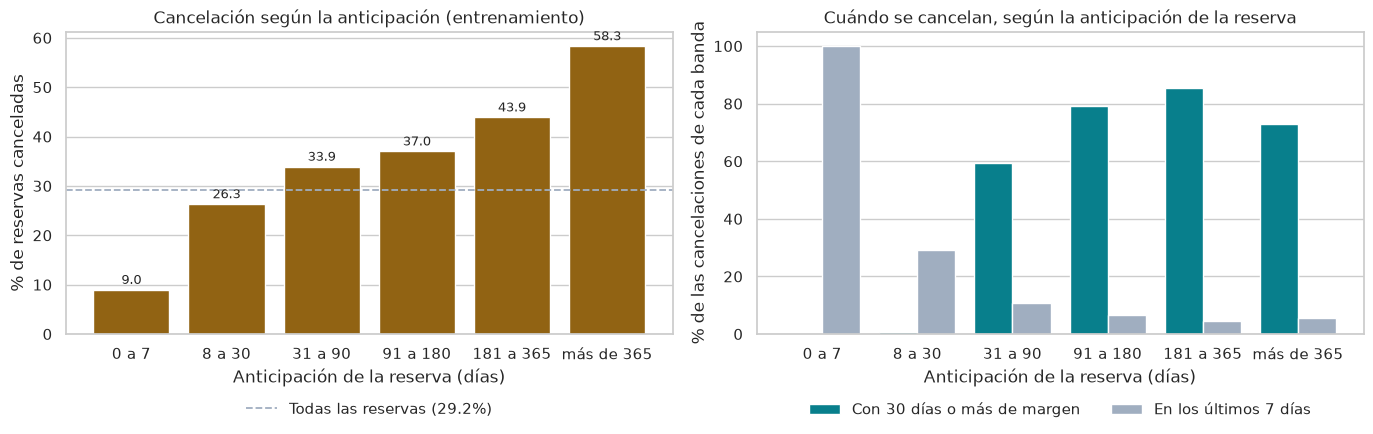

In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.6))

barras = ejes[0].bar(por_anticipacion.index.astype(str), por_anticipacion["cancelación (%)"], color=COLOR_RIESGO)
ejes[0].bar_label(barras, fmt="%.1f", padding=2, fontsize=9)
ejes[0].axhline(y_entrenamiento.mean() * 100, color=COLOR_SECUNDARIO, linestyle="--", linewidth=1.3,
                label=f"Todas las reservas ({y_entrenamiento.mean():.1%})")
ejes[0].set_title("Cancelación según la anticipación (entrenamiento)")
ejes[0].set_xlabel("Anticipación de la reserva (días)")
ejes[0].set_ylabel("% de reservas canceladas")
ejes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False)

con_margen = cuando.drop(index="Todas")[f"con {DIAS_CON_MARGEN} días o más de margen (%)"]
ultima_semana = cuando.drop(index="Todas")[f"en los últimos {DIAS_ULTIMA_SEMANA} días (%)"]
posiciones = np.arange(len(con_margen))
ejes[1].bar(posiciones - 0.2, con_margen, 0.4, color=COLOR_PRINCIPAL, label=f"Con {DIAS_CON_MARGEN} días o más de margen")
ejes[1].bar(posiciones + 0.2, ultima_semana, 0.4, color=COLOR_SECUNDARIO, label=f"En los últimos {DIAS_ULTIMA_SEMANA} días")
ejes[1].set_xticks(posiciones, con_margen.index.astype(str))
ejes[1].set_title("Cuándo se cancelan, según la anticipación de la reserva")
ejes[1].set_xlabel("Anticipación de la reserva (días)")
ejes[1].set_ylabel("% de las cancelaciones de cada banda")
ejes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncols=2, frameon=False)

for ax in ejes:
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**¿Qué vemos?**

- **Entre más anticipación, más cancelación**, como ya había mostrado el notebook 01 con los datos sin limpiar. En el entrenamiento, las reservas de la última semana cancelan el 9,0 %, las de 31 a 90 días el 33,9 % y las de 181 a 365 días el 43,9 %. Las de más de un año llegan al 58,3 %, pero son solo 276 reservas (0,4 %).
- **Por volumen, el problema está en las que se hacen con más de un mes de anticipación**: son el 60,0 % de las reservas y dejan el 76,3 % de las cancelaciones. La banda que más aporta es la de 31 a 90 días (30,8 %), porque junta muchas reservas con una tasa alta.
- **La mayoría de esas cancelaciones llega con tiempo.** De las 24.025 reservas canceladas del CSV original sin filas idénticas, el 95,8 % se canceló y solo el 4,2 % fue *no-show*. La mitad de las cancelaciones se registró 38 días o más antes de la llegada. En las reservas hechas con 91 a 180 días de anticipación, el 79,2 % se canceló con un mes o más de margen, y en las de 181 a 365 días, el 85,3 %. Solo entre el 4,7 % y el 10,7 % de las cancelaciones de las reservas de más de un mes llega en la última semana.
- Las reservas de poca anticipación cancelan poco, pero cuando cancelan es encima de la fecha: en las de 8 a 30 días, el 29,1 % de las cancelaciones llega en la última semana, y en las de la última semana, todas, por definición.

Para el hotel esto cambia el problema. Las reservas que más cancelan casi siempre avisan con semanas de margen, así que esa noche todavía se puede volver a vender si el hotel reacciona rápido. Las cancelaciones que de verdad dejan la habitación vacía son las de último momento y los *no-show*, y esas son pocas.

Lo que no permite concluir: la fecha del estado es la que quedó en el sistema y puede tener demoras de registro. Y saber cuándo cancela la gente no dice que contactarla vaya a evitar la cancelación.

### 2.3 Las agencias

La agencia fue la variable que más usó la SVM (notebook 03, sección 5). Miramos cómo se reparten las reservas y las cancelaciones entre las diez agencias con más reservas.

In [10]:
agencia = entrenamiento["agent"].astype(str).rename("agencia")
por_agencia = cancelacion_por_grupo(agencia).sort_values("reservas", ascending=False)
def mas_frecuente(valores):
    """Valor más frecuente de una columna."""
    return valores.mode().iloc[0]


def porcentaje_del_mas_frecuente(valores):
    """Porcentaje de las reservas que tienen el valor más frecuente."""
    return valores.value_counts(normalize=True).iloc[0] * 100


principales = entrenamiento.groupby(agencia).agg(
    hotel=("hotel", mas_frecuente),
    **{"en ese hotel (%)": ("hotel", porcentaje_del_mas_frecuente)},
    segmento=("market_segment", mas_frecuente),
    **{"en ese segmento (%)": ("market_segment", porcentaje_del_mas_frecuente)},
    anticipacion_mediana=("lead_time", "median"),
)
agencias_principales = por_agencia.head(N_AGENCIAS).join(principales)
display(agencias_principales.round(1))

dos_mayores = por_agencia.drop(index="Sin agente").head(2)
print(f"Agencias con código: {len(por_agencia) - 1}")
print(f"Las {N_AGENCIAS} primeras filas de la tabla: {agencias_principales['reservas (%)'].sum():.1f} % de las reservas "
      f"y {agencias_principales['aporte a las cancelaciones (%)'].sum():.1f} % de las cancelaciones")
print(f"Agencias {' y '.join(dos_mayores.index)}: {dos_mayores['reservas (%)'].sum():.1f} % de las reservas "
      f"y {dos_mayores['aporte a las cancelaciones (%)'].sum():.1f} % de las cancelaciones")

,reservas,reservas (%),cancelación (%),aporte a las cancelaciones (%),hotel,en ese hotel (%),segmento,en ese segmento (%),anticipacion_mediana
agencia,,,,,,,,,
9,21847,34.5,41.1,48.5,City Hotel,100.0,Online TA,100.0,60.0
240,9722,15.3,39.5,20.8,Resort Hotel,100.0,Online TA,99.8,52.5
Sin agente,8272,13.1,14.0,6.2,Resort Hotel,52.8,Direct,48.7,4.0
14,2572,4.1,17.9,2.5,City Hotel,100.0,Direct,100.0,43.0
7,2504,4.0,13.3,1.8,City Hotel,100.0,Online TA,100.0,43.5
250,2168,3.4,17.7,2.1,Resort Hotel,100.0,Direct,100.0,38.0
241,1271,2.0,13.3,0.9,Resort Hotel,100.0,Online TA,99.1,47.0
28,1122,1.8,6.2,0.4,City Hotel,100.0,Offline TA/TO,100.0,47.0
8,1034,1.6,28.8,1.6,City Hotel,81.8,Online TA,81.9,65.5


Agencias con código: 323
Las 10 primeras filas de la tabla: 80.9 % de las reservas y 85.0 % de las cancelaciones
Agencias 9 y 240: 49.8 % de las reservas y 69.2 % de las cancelaciones


**¿Qué vemos?**

- **Dos agencias concentran la mayor parte del problema.** Hay 323 agencias con código, pero las agencias 9 y 240 juntan el 49,8 % de las reservas y el 69,2 % de las cancelaciones. Las dos son agencias en línea (el 100 % y el 99,8 % de sus reservas son *Online TA*) y cada una trabaja con un solo hotel (el 100 % de sus reservas es de ese hotel): la 9 con el City Hotel, donde cancela el 41,1 % de sus reservas, y la 240 con el Resort Hotel, donde cancela el 39,5 %. Las dos están muy por encima del 29,2 % general.
- Las reservas sin agencia, que son el 13,1 %, cancelan solo el 14,0 %, y casi todas las demás agencias grandes quedan entre el 6,2 % y el 17,9 %. La excepción es la 8, con el 28,8 %.
- **La anticipación no lo explica todo.** La agencia 40 tiene la anticipación mediana más alta de la tabla (155 días) y cancela solo el 8,1 %, mientras que la 9, con 60 días, cancela el 41,1 %. Lo más probable es que pesen las condiciones de cada agencia, por ejemplo si deja cancelar gratis hasta el último día, pero el dataset no las trae.

Esto cuadra con lo que vio la SVM, para la que el código de agencia fue la variable más importante (mezclarlo baja el ROC-AUC en 0,111, notebook 03, sección 5). Lo que no permite concluir: que la agencia cause la cancelación. Los códigos están anonimizados y no sabemos qué condiciones ofrece cada una ni qué tipo de cliente atrae.

### 2.4 El historial del cliente y el canal

En la logística, las cancelaciones previas fueron la variable numérica que más subía el riesgo y ser cliente repetido una de las que más lo bajaba (notebook 03, sección 2.4). Aquí miramos cuántas reservas tienen ese historial y cuánto cancelan, y lo mismo para los dos canales principales.

In [11]:
condiciones = {
    "Con cancelaciones previas": entrenamiento["previous_cancellations"].gt(0),
    "Sin cancelaciones previas": entrenamiento["previous_cancellations"].eq(0),
    "Cliente repetido": entrenamiento["is_repeated_guest"].eq(1),
    "Cliente nuevo": entrenamiento["is_repeated_guest"].eq(0),
    "Canal directo (Direct)": entrenamiento["distribution_channel"].eq("Direct"),
    "Canal de agencias (TA/TO)": entrenamiento["distribution_channel"].eq("TA/TO"),
}
historial = pd.DataFrame({
    nombre: {
        "reservas": int(mascara.sum()),
        "reservas (%)": mascara.mean() * 100,
        "cancelación (%)": y_entrenamiento[mascara].mean() * 100,
    }
    for nombre, mascara in condiciones.items()
}).T
historial.round(1)

,reservas,reservas (%),cancelación (%)
Con cancelaciones previas,1285.0,2.0,66.5
Sin cancelaciones previas,62066.0,98.0,28.4
Cliente repetido,2473.0,3.9,8.4
Cliente nuevo,60878.0,96.1,30.1
Canal directo (Direct),9458.0,14.9,15.8
Canal de agencias (TA/TO),50396.0,79.6,32.8


**¿Qué vemos?**

- **El historial dice mucho, pero de pocas reservas.** Las reservas de clientes que ya habían cancelado antes son el 2,0 % y cancelan el 66,5 %, contra el 28,4 % del resto. Los clientes repetidos son el 3,9 % y cancelan solo el 8,4 %, contra el 30,1 % de los nuevos. Es lo mismo que dijo la logística (cancelaciones previas con razón de odds de 7,25 y cliente repetido con 0,38, notebook 03, sección 2.4), visto en porcentajes.
- **El canal directo cancela menos de la mitad que el de agencias**: 15,8 % contra 32,8 %. Pero el canal directo es solo el 14,9 % de las reservas y el de agencias el 79,6 %.

Lo que no permite concluir: que pasar a un cliente al canal directo o volverlo repetido le baje el riesgo. Quien reserva directo o ya conoce el hotel puede ser otro tipo de cliente (en la 4.1 del notebook 04 el perfil de última hora, que es el que más reserva sin agencia, sugería viajes de trabajo).

### 2.5 La cancelación de cada segmento, mes a mes

Para pensar en sobreventa no basta con la tasa promedio de cada segmento: importa cuánto cambia según la época. Calculamos la cancelación de cada segmento de K-Means en cada mes de llegada.

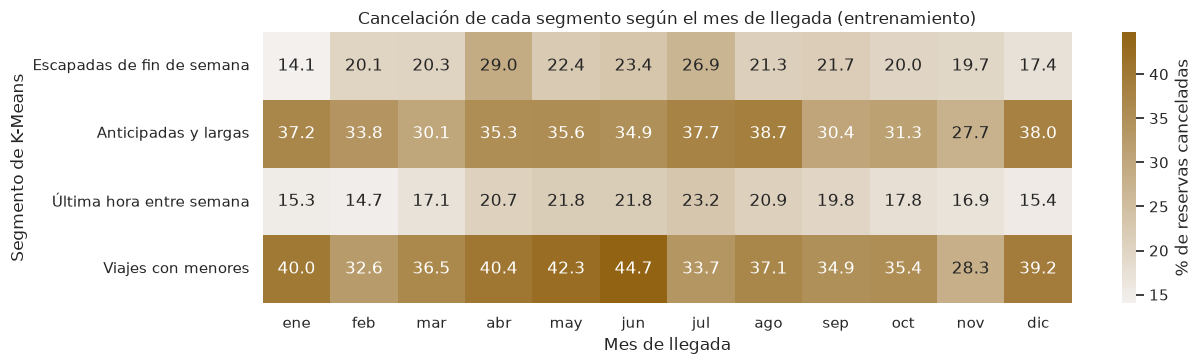

,cancelación promedio (%),mes más bajo (%),mes más alto (%),diferencia (puntos),mes con más cancelación,menos reservas en un mes
segmento,,,,,,
Escapadas de fin de semana,21.6,14.1,29.0,15.0,abr,463
Anticipadas y largas,34.6,27.7,38.7,11.0,ago,1004
Última hora entre semana,18.6,14.7,23.2,8.6,jul,1145
Viajes con menores,37.3,28.3,44.7,16.5,jun,223


In [12]:
segmento_reserva = pd.Series(segmentos, index=entrenamiento.index).map(NOMBRES_SEGMENTOS).rename("segmento")
mes = entrenamiento["mes_llegada"].map(NOMBRES_MESES).rename("mes de llegada")
orden_meses = list(NOMBRES_MESES.values())
orden_segmentos = list(NOMBRES_SEGMENTOS.values())

cancelacion_mes = (pd.crosstab(segmento_reserva, mes, values=y_entrenamiento, aggfunc="mean") * 100).loc[orden_segmentos, orden_meses]
reservas_mes = pd.crosstab(segmento_reserva, mes).loc[orden_segmentos, orden_meses]

fig, ax = plt.subplots(figsize=(13, 3.8))
sns.heatmap(cancelacion_mes, cmap=sns.light_palette(COLOR_RIESGO, as_cmap=True), annot=True, fmt=".1f",
            cbar_kws={"label": "% de reservas canceladas"}, ax=ax)
ax.set_title("Cancelación de cada segmento según el mes de llegada (entrenamiento)")
ax.set_xlabel("Mes de llegada")
ax.set_ylabel("Segmento de K-Means")
plt.tight_layout()
plt.show()

pd.DataFrame({
    "cancelación promedio (%)": y_entrenamiento.groupby(segmento_reserva).mean().loc[orden_segmentos] * 100,
    "mes más bajo (%)": cancelacion_mes.min(axis=1),
    "mes más alto (%)": cancelacion_mes.max(axis=1),
    "diferencia (puntos)": cancelacion_mes.max(axis=1) - cancelacion_mes.min(axis=1),
    "mes con más cancelación": cancelacion_mes.idxmax(axis=1),
    "menos reservas en un mes": reservas_mes.min(axis=1),
}).round(1)

**¿Qué vemos?**

- **La cancelación de cada segmento cambia bastante con la época.** Los viajes con menores van de 28,3 % a 44,7 % según el mes (16,5 puntos de diferencia), las escapadas de fin de semana de 14,1 % a 29,0 % (15,0 puntos), las anticipadas y largas de 27,7 % a 38,7 % (11,0 puntos) y las de última hora entre semana de 14,7 % a 23,2 % (8,6 puntos).
- **El orden de los segmentos sí se mantiene.** En todos los meses las anticipadas y los viajes con menores cancelan más que las escapadas y las de última hora, que es lo mismo que mostró la sección 4.3 del notebook 04 para el año completo.
- El mes con menos reservas para un segmento tiene 223 (viajes con menores), así que cada porcentaje sale de suficientes reservas para no ser casualidad de unas pocas.

Para la sobreventa esto quiere decir que un margen fijo por segmento se equivocaría hasta en 16,5 puntos según el mes. Lo que no permite concluir: que el mismo patrón se repita cada año. El entrenamiento junta llegadas de 2015 a 2017, y cada mes mezcla dos o tres años.

### 2.6 Las estrategias

Proponemos seis estrategias. Para cada una decimos qué haría el hotel, en qué evidencia se apoya y qué no sabemos todavía. Ninguna está probada: los datos muestran asociaciones, no el efecto de una política. Por eso todas deberían arrancar como una prueba con un grupo de control.

**1. Reconfirmar con tiempo las reservas anticipadas de mayor riesgo.**

- *Qué hacer:* a las reservas hechas con más de un mes de anticipación, mandarles un mensaje de reconfirmación varias semanas antes de la llegada, empezando por las que el modelo pone en el cuarto de mayor riesgo de su segmento. Si la reserva se cancela, liberar la habitación de una vez para volverla a vender.
- *En qué nos apoyamos:* esas reservas son el 60,0 % y dejan el 76,3 % de las cancelaciones (2.2). La mayoría cancela con un mes o más de margen (79,2 % en las de 91 a 180 días), así que hay tiempo de revender. Dentro de las anticipadas y largas, el cuarto de mayor riesgo según la logística cancela el 58,8 % y el de menor riesgo el 11,3 % (1.3); con la SVM no hicimos ese cruce, pero ordena un poco mejor que la logística. La SVM detecta tres de cada cuatro cancelaciones con una Precision de 0,486 (notebook 03, sección 4.5), un nivel que sirve para una acción barata como un mensaje y no para una decisión cara.
- *Qué no sabemos:* si el mensaje evita cancelaciones o solo las adelanta. Si las adelanta también sirve, porque deja más tiempo para revender, pero hay que medirlo.

**2. Revisar las condiciones con las agencias 9 y 240.**

- *Qué hacer:* negociar con esas dos agencias plazos de cancelación gratuita más cortos, que las habitaciones que no se van a usar se liberen con más anticipación y un reporte periódico de cancelaciones. Hacerle seguimiento mensual a la tasa de cada agencia grande.
- *En qué nos apoyamos:* juntan el 49,8 % de las reservas y el 69,2 % de las cancelaciones, y cancelan el 41,1 % y el 39,5 % (2.3). La agencia fue la variable que más usó la SVM (notebook 03, sección 5). Y la agencia 40, con más anticipación, cancela mucho menos (8,1 %), así que hay margen para que las condiciones importen.
- *Qué no sabemos:* qué condiciones tienen hoy esas agencias. Endurecerlas puede bajar el número de reservas que traen, y son las que más reservas traen.

**3. Darles beneficios a los clientes repetidos y a las reservas directas.**

- *Qué hacer:* un programa sencillo de fidelización, con tarifas o beneficios por reservar directo y para quien vuelve, y la opción de cambiar la fecha en lugar de cancelar.
- *En qué nos apoyamos:* los clientes repetidos cancelan el 8,4 % y los nuevos el 30,1 %; el canal directo cancela el 15,8 % y el de agencias el 32,8 % (2.4).
- *Qué no sabemos:* si la diferencia es por el canal o por el tipo de cliente. Es la estrategia con la evidencia más débil para la causa, aunque también la más barata de probar.

**4. Pedir una garantía a quien ya ha cancelado antes.**

- *Qué hacer:* pedir una tarjeta de garantía o un depósito pequeño cuando el cliente tiene cancelaciones previas con el hotel.
- *En qué nos apoyamos:* esas reservas cancelan el 66,5 %, contra el 28,4 % del resto (2.4), y en la logística cada cancelación previa multiplica los odds por 7,25 (notebook 03, sección 2.4).
- *Qué no sabemos:* el alcance es pequeño, porque son el 2,0 % de las reservas. Es una medida puntual, no la solución al problema.

**5. Sobreventa por segmento y por mes, y con prudencia.**

- *Qué hacer:* fijar cuántas habitaciones se sobrevenden según la cancelación observada de cada segmento en cada época, con un colchón de seguridad, y revisarla cada mes con datos nuevos. No usar el puntaje de la SVM como probabilidad para esto.
- *En qué nos apoyamos:* la cancelación de cada segmento se sostiene de entrenamiento a prueba (21,6 % y 22,1 % en las escapadas, 34,6 % y 35,3 % en las anticipadas, notebook 04, sección 4.3), y los segmentos salen casi iguales con otras muestras (ARI de 0,991). Pero dentro de un segmento la tasa cambia hasta 16,5 puntos de un mes a otro (2.5). La SVM no da probabilidades (notebook 03, sección 3.1), y para sobrevender una falsa alarma sale cara: termina en un huésped sin habitación, por eso la 4.6 del notebook 03 recomienda un corte más alto en ese uso.
- *Qué no sabemos:* el costo real de reubicar a un huésped, que es el que define el colchón. Las tasas son de 2015 a 2017.

**6. Probar los depósitos antes de imponerlos.**

- *Qué hacer:* no poner depósitos sin reembolso para todos. Probar un depósito parcial solo en reservas anticipadas de alto riesgo, en un grupo al azar, y compararlo con otro grupo sin depósito, midiendo cancelaciones y reservas perdidas.
- *En qué nos apoyamos:* el depósito *Non Refund* cancela el 94,7 % sin duplicados (notebook 01, sección 3.3), pero no porque el depósito haga cancelar: casi todas esas reservas son bloqueos de agencias que se liberan en bloque. O sea que los datos no dicen qué efecto tiene un depósito, y la única manera de saberlo es probarlo.
- *Qué no sabemos:* cuántos clientes que sí iban a llegar se pierden por pedir el depósito, que es el costo que mencionamos en la 1.1 del notebook 01.

| Estrategia | A qué reservas apunta | Evidencia principal | Alcance |
|---|---|---|---|
| 1. Reconfirmar con tiempo | Más de un mes de anticipación, empezando por el cuarto de mayor riesgo | 76,3 % de las cancelaciones; la mayoría cancela con un mes o más de margen | Grande |
| 2. Condiciones con agencias | Agencias 9 y 240 | 69,2 % de las cancelaciones | Grande |
| 3. Fidelizar y canal directo | Clientes repetidos y reservas directas | 8,4 % y 15,8 % de cancelación | Medio, a largo plazo |
| 4. Garantía por historial | Clientes con cancelaciones previas | 66,5 % de cancelación | Pequeño |
| 5. Sobreventa por segmento y mes | Los cuatro segmentos | Tasas estables entre entrenamiento y prueba, pero hasta 16,5 puntos de cambio por mes | Medio, con riesgo |
| 6. Prueba de depósitos | Anticipadas de alto riesgo | Sin evidencia de efecto: hay que medirlo | Por definir |

**Por dónde empezar:** por la 1 y la 2. Son las que más cancelaciones tocan y, en el caso de la 1, la más barata. Las dos se pueden medir en pocos meses comparando con un grupo que no reciba la acción.

## 3. Conclusiones

### 3.1 Limitaciones

- **Dos hoteles de Portugal, de 2015 a 2017.** Son un hotel de ciudad en Lisboa y uno de playa en el Algarve, antes de la pandemia. Lo que encontramos describe a esos dos hoteles en esos años. Para un hotel de Medellín, por ejemplo, habría que repetir el análisis con sus propios datos.
- **El modelo pierde fuerza con el tiempo.** Entrenando con 2015-2016 y probando con llegadas de 2017, el ROC-AUC de la SVM bajó de cerca de 0,77 a 0,729 (notebook 03, sección 6.2). Un modelo así hay que reentrenarlo y vigilarlo.
- **No sabemos en qué momento se llena cada campo.** Por eso sacamos el país, el parqueadero, la habitación asignada y los cambios de la reserva (notebook 01, sección 3.8, y notebook 02, sección 3). Con eso evitamos la fuga, pero también perdimos información que quizás sí se conoce al reservar.
- **Duplicados sin número de reserva.** El CSV tenía 31.994 filas idénticas a otra, y no hay forma de saber cuáles son copias y cuáles habitaciones reales de un grupo. Según cómo se traten, la cancelación es de 37,0 % o de 29,2 %.
- **Faltan variables que probablemente pesan.** El dataset no trae las condiciones de cancelación de cada agencia y tarifa, los precios de la competencia, el motivo del viaje, ni cómo y cuándo se comunicó el hotel con el cliente. Además, la tarifa y el depósito quedaron por fuera de los modelos.
- **Las clases se traslapan mucho.** Hay 1.713 perfiles con exactamente las mismas entradas en los que unas reservas se cancelaron y otras no (notebook 03, sección 3.3). Con estas variables, ningún modelo va a acertar mucho más.
- **Los segmentos tienen una estructura débil** (Silhouette de 0,249) y dos métodos distintos coinciden poco (ARI de 0,281 entre K-Means y Ward). Son una forma útil de ordenar las reservas, no tipos naturales.
- **Asociación no es causalidad.** Todo lo que encontramos son relaciones en datos históricos. Las estrategias de la sección 2 son hipótesis que hay que probar, no efectos medidos.
- **Los costos de los errores los supusimos.** El corte del modelo se escogió con F1 y con razones de costo inventadas para ver cómo se movía (notebook 03, sección 4.6). Con los costos reales del hotel, el corte puede cambiar.

### 3.2 Respuestas a las preguntas del notebook 01

**1. ¿Qué características de una reserva permiten anticipar que se va a cancelar?**

Las que más pesan son **la agencia y la anticipación**. Para la SVM, mezclar el código de agencia baja el ROC-AUC en 0,111 y mezclar la anticipación en 0,063 (notebook 03, sección 5). Dos agencias en línea concentran el 69,2 % de las cancelaciones (2.3), y la cancelación sube del 9,0 % en la última semana al 43,9 % entre 181 y 365 días (2.2). Después vienen **el historial del cliente** (las cancelaciones previas multiplican los odds por 7,25 y ser cliente repetido por 0,38), **el hotel** (el City Hotel tiene el doble de odds que el Resort, razón de 1,99) y **el canal**: el directo cancela el 15,8 % y el de agencias el 32,8 % (notebook 03, sección 2.4, y 2.4 de este notebook).

Varias variables que parecían predecir casi perfecto resultaron ser fuga de información o dudosas, y las sacamos: el estado de la reserva, la habitación asignada, el parqueadero, el depósito y el país (notebook 01, sección 3.8, y notebook 02, sección 3).

**2. ¿Qué tan bien se puede predecir una cancelación solo con lo que se sabe al momento de reservar?**

Moderadamente. En prueba, la SVM tiene un F1 de 0,590, Recall de 0,750, Precision de 0,486 y ROC-AUC de 0,771 (notebook 03, sección 4.5). Detecta tres de cada cuatro cancelaciones, pero de cada dos reservas que marca, una sí llega. Sirve para ordenar las reservas y decidir a cuáles ponerles atención, pero no para tomar una decisión sobre una reserva sola. El límite no está en el algoritmo: el ajuste de hiperparámetros mejoró poco y las clases se traslapan mucho con lo que se sabe al reservar.

**3. ¿Qué perfiles de reservas existen?**

Con K-Means encontramos cuatro (notebook 04, sección 4): **escapadas de fin de semana** (13,4 %), **anticipadas y largas** (45,5 %), **última hora entre semana** (25,5 %) y **viajes con menores** (15,5 %). Los segmentos salen casi iguales con otras muestras (ARI de 0,991), pero la estructura es débil (Silhouette de 0,249). Los perfiles más sólidos son los de estancias cortas, entre semana y de fin de semana, porque también los encontró el agrupamiento jerárquico, que funciona distinto.

**4. ¿Cómo se relacionan esos perfiles con las cancelaciones y qué estrategias sugieren?**

Los perfiles que se reservan con tiempo cancelan más que el promedio de 29,2 %: los viajes con menores el 37,3 % y las anticipadas y largas el 34,6 %. Los de poca anticipación cancelan menos: las escapadas el 21,6 % y las de última hora el 18,6 % (notebook 04, sección 4.3). La relación es débil (V de Cramér de 0,170), y dentro de cada perfil el riesgo cambia mucho (1.3). Por volumen, las anticipadas y largas juntan el 54,0 % de las cancelaciones, y en todos los meses los dos perfiles de arriba cancelan más que los dos de abajo (2.5).

Las estrategias que sugieren están en la sección 2. Lo principal es concentrarse en las reservas anticipadas, que cancelan más pero casi siempre con tiempo de revender, y en las dos agencias que más cancelan.

### 3.3 Recomendación final

Al hotel le recomendamos usar los dos enfoques juntos, cada uno para lo que sirve:

1. **El modelo supervisado para ordenar las reservas por riesgo cuando entran.** La SVM es la que mejor lo hace. La logística es una alternativa razonable si el hotel necesita explicar sus decisiones o reentrenar seguido, porque queda apenas por debajo (F1 de 0,575 contra 0,590 en prueba).
2. **Los segmentos para repartir la atención y fijar políticas por perfil**, y el puntaje del modelo para escoger a qué reservas atender primero dentro de cada segmento.
3. **Empezar por dos acciones de bajo costo**, cada una con un grupo de control para medir el efecto: reconfirmar con tiempo las reservas anticipadas de mayor riesgo y revisar las condiciones con las agencias 9 y 240. Dejar la sobreventa por segmento y los depósitos para cuando se conozcan los costos reales y se haya hecho una prueba.
4. **Antes de usar el modelo en la operación**, probarlo con reservas recientes, confirmar con el hotel qué campos existen en el momento de reservar y escoger el corte con sus costos reales, no con el F1.

El modelo no reemplaza el criterio del área comercial. Lo que hace es decirle por dónde empezar, en un problema donde el 76,3 % de las cancelaciones viene de reservas que avisan con suficiente tiempo para hacer algo.